# 06 · Un solo modelo multi-etiqueta para H1, H4, H5 y H6

Generado por `PYTHONPATH=src python -m usab_ds stage6`. Mismo protocolo que el notebook 05: partición 70/30 por participante; estrategia, estimador, variables y umbrales elegidos **solo** con validación cruzada en el 70 %; el 30 % se evalúa una vez.

In [1]:
import pathlib, sys, joblib
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))     # necesario para cargar la clase del modelo
R = ROOT / 'reports' / '06_modelo_multietiqueta'
pd.set_option('display.width', 220)
per = pd.read_csv(R / 'resultados_test_30_por_heuristica.csv'); glob = pd.read_csv(R / 'resultados_test_30_global.csv')
cv = pd.read_csv(R / 'comparacion_cv_70.csv'); pred = pd.read_csv(R / 'predicciones_test.csv')
glob.round(3)

,estrategia,estimador,variables,f1_macro,mcc_macro,f1_micro_H1H4H6,hamming_loss_H1H4H6,exact_match_H1H4H6
0,joint,Random Forest,completo+intra_participante,0.707,0.545,0.663,0.222,0.548


## 1. Desempeño por heurística (30 % de prueba)

In [2]:
per[['heuristica','n','positivos','umbral','exactitud','exactitud_balanceada','precision','sensibilidad','especificidad','f1','mcc','kappa','roc_auc','pr_auc']].round(3)

,heuristica,n,positivos,umbral,exactitud,exactitud_balanceada,precision,sensibilidad,especificidad,f1,mcc,kappa,roc_auc,pr_auc
0,H1,93,32,0.481,0.860,0.849,0.788,0.812,0.885,0.800,0.693,0.693,0.856,0.855
1,H4,93,17,0.400,0.731,0.721,0.375,0.706,0.737,0.490,0.360,0.330,0.824,0.666
2,H5,18,11,0.341,0.833,0.786,0.786,1.000,0.571,0.880,0.670,0.620,0.870,0.912
3,H6,93,32,0.457,0.742,0.736,0.605,0.719,0.754,0.657,0.457,0.453,0.847,0.776


In [3]:
per[['heuristica','f1_ic95','mcc_ic95','sensibilidad_ic95','especificidad_ic95','roc_auc_ic95','mcnemar_p_vs_base']]

,heuristica,f1_ic95,mcc_ic95,sensibilidad_ic95,especificidad_ic95,roc_auc_ic95,mcnemar_p_vs_base
0,H1,"[0.727, 0.868]","[0.614, 0.801]","[0.744, 0.952]","[0.813, 0.982]","[0.804, 0.939]",0.001319
1,H4,"[0.349, 0.690]","[0.193, 0.639]","[0.545, 1.000]","[0.493, 0.962]","[0.736, 0.968]",0.215327
2,H5,"[0.783, 0.963]","[0.471, 0.880]","[1.000, 1.000]","[0.333, 0.833]","[0.741, 1.000]",0.125000
3,H6,"[0.538, 0.800]","[0.195, 0.710]","[0.524, 0.931]","[0.610, 0.890]","[0.726, 0.949]",0.255875


In [4]:
m = ['exactitud','exactitud_balanceada','precision','sensibilidad','especificidad','f1','mcc','kappa','roc_auc','pr_auc']
(per.set_index('heuristica')[m] > 0.85).replace({True: '✔', False: ''})

,exactitud,exactitud_balanceada,precision,sensibilidad,especificidad,f1,mcc,kappa,roc_auc,pr_auc
heuristica,,,,,,,,,,
H1,✔,,,,✔,,,,✔,✔
H4,,,,,,,,,,
H5,,,,✔,,✔,,,✔,✔
H6,,,,,,,,,,


## 2. Comparación de estrategias multi-etiqueta (validación cruzada en el 70 %)

In [5]:
cv.round(3)

,estrategia,estimador,variables,cv_f1_macro,cv_mcc_macro,cv_f1_micro_H1H4H6,cv_hamming_loss_H1H4H6,cv_exact_match_H1H4H6,umbrales
0,joint,Random Forest,completo+intra_participante,0.629,0.454,0.585,0.236,0.553,"{""H1"": 0.481, ""H4"": 0.4, ""H5"": 0.341, ""H6"": 0...."
1,binary_relevance,Extra Trees,completo+intra_participante,0.617,0.441,0.568,0.245,0.488,"{""H1"": 0.382, ""H4"": 0.365, ""H5"": 0.354, ""H6"": ..."
2,joint,Red Neuronal (MLP),completo+intra_participante,0.616,0.433,0.535,0.278,0.474,"{""H1"": 0.048, ""H4"": 0.025, ""H5"": 0.435, ""H6"": ..."
3,chain,Extra Trees,completo+intra_participante,0.625,0.433,0.522,0.349,0.265,"{""H1"": 0.382, ""H4"": 0.144, ""H5"": 0.333, ""H6"": ..."
4,joint,Extra Trees,completo+intra_participante,0.615,0.420,0.500,0.394,0.186,"{""H1"": 0.443, ""H4"": 0.124, ""H5"": 0.339, ""H6"": ..."
5,binary_relevance,Regresión Logística,completo+intra_participante,0.613,0.414,0.543,0.282,0.414,"{""H1"": 0.451, ""H4"": 0.515, ""H5"": 0.355, ""H6"": ..."
6,chain,Random Forest,completo+intra_participante,0.621,0.412,0.510,0.420,0.130,"{""H1"": 0.354, ""H4"": 0.07, ""H5"": 0.34, ""H6"": 0...."
7,binary_relevance,Random Forest,completo+intra_participante,0.619,0.408,0.508,0.423,0.121,"{""H1"": 0.354, ""H4"": 0.073, ""H5"": 0.345, ""H6"": ..."
8,binary_relevance,Random Forest,completo,0.614,0.404,0.504,0.412,0.135,"{""H1"": 0.378, ""H4"": 0.068, ""H5"": 0.429, ""H6"": ..."
9,chain,Regresión Logística,completo+intra_participante,0.613,0.404,0.543,0.295,0.377,"{""H1"": 0.451, ""H4"": 0.469, ""H5"": 0.238, ""H6"": ..."


## 3. Curvas ROC y matrices de confusión

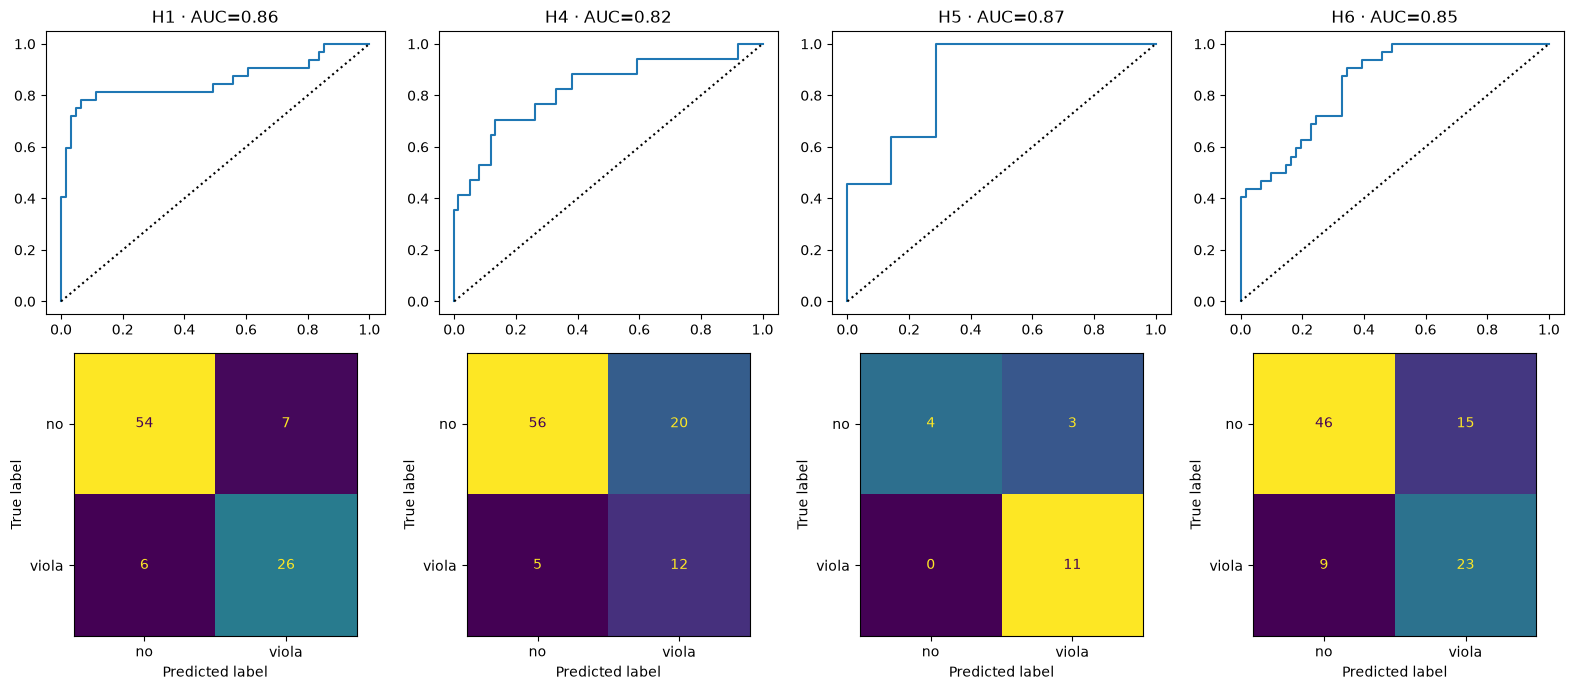

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, (_, r) in enumerate(per.iterrows()):
    h = r.heuristica; d = pred[pred[f'real_y_{h}'].notna()]
    y, p = d[f'real_y_{h}'].astype(int), d[f'prob_y_{h}']
    fpr, tpr, _ = roc_curve(y, p)
    axes[0, i].plot(fpr, tpr); axes[0, i].plot([0, 1], [0, 1], 'k:'); axes[0, i].set_title(f'{h} · AUC={r.roc_auc:.2f}')
    ConfusionMatrixDisplay.from_predictions(y, (p >= r.umbral).astype(int), ax=axes[1, i], colorbar=False,
                                            display_labels=['no', 'viola'])
plt.tight_layout()

## 4. Usar el modelo: una sesión → cuatro predicciones

In [7]:
b = joblib.load(ROOT / 'models' / 'modelo_multietiqueta_H1_H4_H5_H6.joblib')
print(b['strategy'], '·', b['base'], '· umbrales:', {k: round(v, 3) for k, v in b['thresholds'].items()})
df = pd.read_parquet(ROOT / 'data/processed/usab_v2/training/training_dataset.parquet')
df = df[df.include_main].reset_index(drop=True)
num = [c for c in b['features'] if not c.startswith('intra_')]
base_cols = [c[len('intra_'):] for c in b['features'] if c.startswith('intra_')]
df = pd.concat([df, df.groupby('participant_id')[base_cols].rank(pct=True).add_prefix('intra_')], axis=1)
ejemplo = df.sample(5, random_state=1)
P = b['model'].predict_proba_frame(ejemplo[b['features']].to_numpy(dtype=float))
pd.concat([ejemplo[['session_id']].reset_index(drop=True), P.round(3), b['model'].predict(ejemplo[b['features']].to_numpy(dtype=float)).add_suffix('_pred')], axis=1)

joint · Random Forest · umbrales: {'y_H1': 0.481, 'y_H4': 0.4, 'y_H5': 0.341, 'y_H6': 0.457}


,session_id,y_H1,y_H4,y_H5,y_H6,y_H1_pred,y_H4_pred,y_H5_pred,y_H6_pred
0,S02_a11y_cua:BLVU/BLVU5/1,0.244,0.087,0.626,0.136,0,0,1,0
1,S02_a11y_cua:SU/SU8/6,0.221,0.483,0.704,0.338,0,1,1,0
2,S02_a11y_cua:SU/SU4/6,0.141,0.600,0.907,0.186,0,1,1,0
3,S02_a11y_cua:SU/SU5/40,0.697,0.832,0.369,0.815,1,1,1,1
4,S02_a11y_cua:SU/SU6/5,0.473,0.405,0.657,0.618,0,1,1,1
